# EDA 

This notebook donloads the inptu data, investigates it and addes some noises and then finally serializes to share with the students. 



In [45]:
import os
import shutil
from pathlib import Path

import numpy as np
import pandas as pd

In [9]:
df_images_count = pd.read_csv('data/lfw_allnames.csv')

<Axes: >

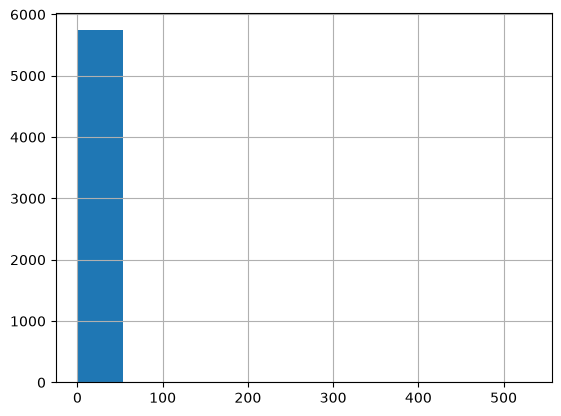

In [19]:
df_images_count.images.hist()

In [21]:
df_images_count.images.max()

np.int64(530)

In [41]:
df = df_images_count[(df_images_count.images>4) & (df_images_count.images< 100)]

In [42]:
df

,name,images
20,Abdullah_Gul,19
52,Adrien_Brody,12
60,Ahmed_Chalabi,5
67,Ai_Sugiyama,5
84,Al_Gore,8
...,...,...
5688,Yasser_Arafat,8
5697,Yoko_Ono,6
5704,Yoriko_Kawaguchi,14
5738,Zhu_Rongji,9


In [49]:
RNG = np.random.RandomState(42)

# Shuffle identities
df = df.sample(frac=1.0, random_state=42).reset_index(drop=True)

n_total = len(df)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)

train_df = df.iloc[:n_train]
val_df = df.iloc[n_train : n_train + n_val]
test_df = df.iloc[n_train + n_val :]

print(f"Total Identities: {n_total}")
print(f"  Train: {len(train_df)} identities ({train_df.images.sum()} images)")
print(f"  Val:   {len(val_df)} identities ({val_df.images.sum()} images)")
print(f"  Test:  {len(test_df)} identities ({test_df.images.sum()} images)")

# 2. Build directories
base_src = Path("data/lfw-deepfunneled/lfw-deepfunneled")
base_dest = Path("data/for_students/faces")

for split_name, split_df in [("train", train_df), ("val", val_df)]:
    for name in split_df["name"]:
        src_dir = base_src / name
        dest_dir = base_dest / split_name / name
        shutil.copytree(src_dir, dest_dir, dirs_exist_ok=True)

# 3. Special handling for TEST: setup the Smart Gate scenario
# Let's pick half of test identities to be "Staff" (enrolled), and half to be "Impostors"
test_identities = test_df["name"].tolist()
n_staff = len(test_identities) // 2
staff_names = test_identities[:n_staff]
impostor_names = test_identities[n_staff:]

gate_gallery_dir = base_dest / "test" / "gate_gallery"  # Enrolled DB
gate_probe_dir = base_dest / "test" / "gate_probes"    # Query attempts

gate_gallery_dir.mkdir(parents=True, exist_ok=True)
(gate_probe_dir / "authorized").mkdir(parents=True, exist_ok=True)
(gate_probe_dir / "impostors").mkdir(parents=True, exist_ok=True)

# Enroll staff (1st image -> gallery, remaining images -> authorized probes)
for name in staff_names:
    src_dir = base_src / name
    img_files = sorted(os.listdir(src_dir))

    # Image 0 is enrolled into gate database
    shutil.copy2(src_dir / img_files[0], gate_gallery_dir / f"{name}_0001.jpg")

    # Images 1+ are used to test True Acceptance Rate
    for img in img_files[1:]:
        shutil.copy2(src_dir / img, gate_probe_dir / "authorized" / f"{name}_{img}")

# Impostors (never enrolled in gallery -> used to test False Acceptance Rate)
for name in impostor_names:
    src_dir = base_src / name
    for img in os.listdir(src_dir):
        shutil.copy2(src_dir / img, gate_probe_dir / "impostors" / f"{name}_{img}")

# Save manifest CSVs for student verification & testing
train_df.to_csv(base_dest / "train_identities.csv", index=False)
val_df.to_csv(base_dest / "val_identities.csv", index=False)
test_df.to_csv(base_dest / "test_identities.csv", index=False)
print("Data split complete and saved to data/split/")


Total Identities: 418
  Train: 292 identities (3399 images)
  Val:   62 identities (758 images)
  Test:  64 identities (688 images)
Data split complete and saved to data/split/
